<a href="https://colab.research.google.com/github/Sanika515/AIML/blob/main/9_Object_Detection_using_YOLO_Fruits_and_vegetables_https_www_kaggle_com_datasets_kritikseth_fruit_and_vegetable_image_recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install ultralytics kagglehub
import kagglehub
path = kagglehub.dataset_download('kritikseth/fruit-and-vegetable-image-recognition')
print(path)

Using Colab cache for faster access to the 'fruit-and-vegetable-image-recognition' dataset.
/kaggle/input/fruit-and-vegetable-image-recognition


In [ ]:
import os, glob, random, shutil
import matplotlib.pyplot as plt
IMG_EXT = ('.png', '.jpg', '.jpeg', '.bmp')

# find the folder that holds train / validation / test
src = path
for r, d, f in os.walk(path):
    if 'train' in d:
        src = r; break
print(src, os.listdir(src))

# build a writable folder with train / val / test links (the original folder is read-only)
root = os.path.abspath('fruitveg')
shutil.rmtree(root, ignore_errors=True); os.makedirs(root)
for new, old in (('train', 'train'), ('val', 'validation'), ('test', 'test')):
    if os.path.exists(os.path.join(src, old)):
        os.symlink(os.path.join(src, old), os.path.join(root, new))
print(os.listdir(root))
print("classes:", len(os.listdir(os.path.join(root, 'train'))))

/kaggle/input/fruit-and-vegetable-image-recognition ['validation', 'test', 'train']
['test', 'val', 'train']
classes: 36


In [ ]:
from ultralytics import YOLO

model = YOLO('yolov8n-cls.pt')
results = model.train(data=root, epochs=1, imgsz=128, batch=16, workers=0)

Ultralytics 8.4.218 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fruitveg, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=128, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-5, nbs=64, nms=None, opset=None, optimize=False, optimizer=au

Ultralytics 8.4.218 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv8n-cls summary (fused): 30 layers, 1,480,996 parameters, 0 gradients, 3.3 GFLOPs
train: /content/fruitveg/train... found 3115 images in 36/36 classes ✅ 
val: /content/fruitveg/val... found 351 images in 36/36 classes ✅ 
test: /content/fruitveg/test... found 359 images in 36/36 classes ✅ 
val: Fast image access ✅ (ping: 1.4±0.9 ms, read: 158.4±54.1 MB/s, size: 1234.9 KB)
val: Scanning /content/fruitveg/val... 351 images, 0 corrupt: 100% ━━━━━━━━━━━━ 351/351 6.7Mit/s 0.0s
               classes   top1_acc   top5_acc: 100% ━━━━━━━━━━━━ 22/22 1.3s/it 29.3s
                   all      0.741      0.934
Speed: 0.0ms preprocess, 4.9ms inference, 0.0ms loss, 0.0ms postprocess per image
Results saved to /content/runs/classify/val
Top-1 accuracy: 0.7407407164573669  Top-5 accuracy: 0.934472918510437


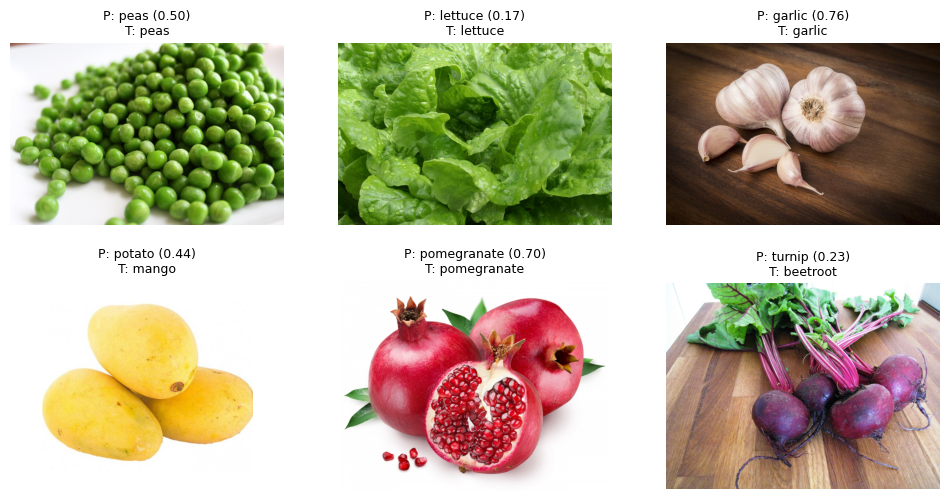

In [ ]:
metrics = model.val()
print("Top-1 accuracy:", metrics.top1, " Top-5 accuracy:", metrics.top5)

test_files = glob.glob(os.path.join(root, 'test', '*', '*'))
test_files = [f for f in test_files if f.lower().endswith(IMG_EXT)]
plt.figure(figsize=(12, 6))
for i, f in enumerate(random.sample(test_files, 6)):
    r = model.predict(f, verbose=False)[0]
    plt.subplot(2, 3, i + 1); plt.imshow(plt.imread(f)); plt.axis('off')
    plt.title(f"P: {r.names[r.probs.top1]} ({float(r.probs.top1conf):.2f})\nT: {os.path.basename(os.path.dirname(f))}", fontsize=9)
plt.show()

In [ ]:
1. What is the problem?

Given a photo of a fruit or vegetable, the computer must say which one it is. There are 36 different kinds, such as apple, banana, carrot, tomato, beetroot, cabbage and chilli pepper.

2. The dataset

From your own run, we saw:

36 classes.
About 3,115 training, 351 validation and 359 test images.
The images are sorted into folders: train/<class>/, validation/<class>/, test/<class>/. The folder name is the label.
The images are large photos, some thousands of pixels wide. (That is why caching images in RAM crashed your session. We removed cache=True.)

Same honest point as Problem 7: this dataset has only class labels and no bounding boxes. So we use YOLOv8 in classification mode (yolov8n-cls).

If the examiner asks: "The dataset has only image-level labels, with no box annotations, so I used YOLOv8's classification mode. With box labels I would use the detection model in the same way."

3. What is the solution?

It is the same as Problem 7, with more classes (36 instead of 5). We take yolov8n-cls.pt, pre-trained on ImageNet, and fine-tune it on our 36 classes.

When YOLO loads the model, your screenshot showed this line:

Overriding model.yaml nc=1000 with nc=36

That means the original model had 1000 output classes (ImageNet), and YOLO replaced the final layer with a 36-class one. This is exactly transfer learning: the backbone keeps its knowledge and only the last layer is new. You can point to it in the exam.

Your screenshot also showed: Transferred 156/158 items from pretrained weights. That means 156 of the 158 weight tensors were copied from the pre-trained model. The 2 left over are the final classification layer, which is new.
#############code#################
Step 1: Install and download

python
!pip -q install ultralytics kagglehub
path = kagglehub.dataset_download('kritikseth/fruit-and-vegetable-image-recognition')

Step 2: Prepare the folders

python
root = os.path.abspath('fruitveg')
for new, old in (('train','train'), ('val','validation'), ('test','test')):
    os.symlink(os.path.join(src, old), os.path.join(root, new))

YOLO looks for a folder named val, but this dataset calls it validation. We build a small writable folder fruitveg with links named train, val and test that point to the real data. (We can't edit the original, since it is read-only.)

Step 3: Train

python
from ultralytics import YOLO
model = YOLO('yolov8n-cls.pt')
results = model.train(data=root, epochs=5, imgsz=128, batch=16, workers=0)
imgsz=128: images are shrunk to 128×128. The big photos become small, so training is fast.
batch=16, workers=0: lower RAM use, to avoid the crash.
epochs=5: five passes. (Use 1 on CPU for testing.)

Step 4: Evaluate and predict

python
metrics = model.val()
print("Top-1 accuracy:", metrics.top1, " Top-5 accuracy:", metrics.top5)
r = model.predict(f)[0]
r.names[r.probs.top1], float(r.probs.top1conf)
Top-1: the best guess is the right fruit or vegetable.
Top-5: the right answer is within the 5 best guesses. With 36 classes this number is meaningful and is usually very high (about 99%).
The last cell shows 6 test images with the predicted class, confidence and true class.
5. The output you will see
train: ... found 3115 images in 36/36 classes ✅, the same for val and test.
Overriding model.yaml nc=1000 with nc=36.
The model summary: 56 layers, 1,484,404 parameters.
Transferred 156/158 items from pretrained weights.
Warnings about a few "corrupt images" being ignored. This is harmless: about 6 broken images are skipped (one is really a GIF named .jpg).
A training table per epoch with loss falling and accuracy_top1 rising.
Top-1 accuracy of roughly 90–96% and top-5 around 99% after 5 epochs. I haven't seen your real result, so go by your own number.
Six test images with P: name (confidence) and T: true name.

If a prediction is wrong or has low confidence: the usual cause is a look-alike pair such as cabbage and cauliflower, or chilli and capsicum. The softmax spreads probability across similar classes. This is good to mention.

6. What to tell the examiner (30-second version)

"This dataset has 36 fruit and vegetable classes with image-level labels and no bounding boxes, so I used YOLOv8 in classification mode, starting from the pre-trained yolov8n-cls model. YOLO replaced its 1000-class ImageNet output with a 36-class layer, and I fine-tuned it at 128×128 for 5 epochs. The backbone uses Conv and C2f blocks and the classify head uses pooling and a linear layer with softmax. I evaluated it with top-1 and top-5 accuracy and predicted sample test images with their confidence."
###############################BLOCK######################3
          START
            |
            v
    Load Fruit & Vegetable
          Dataset
            |
            v
       Prepare Dataset
     Train / Val / Test
            |
            v
      Load YOLOv8 Model
      (yolov8n-cls.pt)
            |
            v
        Preprocessing
            |
            v
       Feature Extraction
            |
            v
     Classification Head
            |
            v
        Train Model
            |
            v
       Validate Model
            |
            v
      Calculate Accuracy
       (Top-1 / Top-5)
            |
            v
     Predict Food Category
            |
            v
           STOP
##################################### Questions the examiner may ask
Why is YOLO used here if there are no boxes? YOLOv8 has a classification mode that uses the same backbone design. Box labels would let us use the detection model.
What is nc=36? The number of classes. YOLO replaced the original 1000-class head with a 36-class one.
What are train, validation and test sets? Train is for learning, validation is for monitoring during training, and test is for the final unbiased check.
Why resize to 128×128? Faster training and less memory. A larger size gives more accuracy but is slower.
Why did you set workers=0? To keep RAM use low, because the photos are very large. Higher workers load images in parallel but use more memory.
What are top-1 and top-5 accuracy? Top-1: the single best guess is correct. Top-5: the right class is in the 5 best guesses.
What is the loss used? Cross-entropy between the predicted probabilities and the true class.
Which optimiser does YOLO use? By default auto, which picks AdamW for short training runs and SGD for longer ones.
How would you improve accuracy? More epochs, a larger image size, a bigger model such as yolov8s-cls, and more augmentation.
Epoch vs iteration? An epoch is one pass over all training images. An iteration is one batch update (3,115 ÷ 16 ≈ 195 per epoch).